(C) Copyright 2025 - ECMWF and individual contributors.

This software is licensed under the terms of the Apache Licence Version 2.0
which can be obtained at http://www.apache.org/licenses/LICENSE-2.0.
In applying this licence, ECMWF does not waive the privileges and immunities
granted to it by virtue of its status as an intergovernmental organisation nor
does it submit to any jurisdiction.

# POF Plotter

Importing all the necessary python libraries

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib import cm
from matplotlib.colors import Normalize
import numpy as np
import xarray as xr
import matplotlib as mpl
from cartopy import config
import cartopy.crs as ccrs
import cartopy as cart
import sys
import datetime
from matplotlib.colors import ListedColormap,LinearSegmentedColormap


Open Prediction Netcdf

In [ ]:
run_date = datetime.date.today() - datetime.timedelta(days=1)


fire= xr.open_dataset(f"./outputs/POF_prediction_{run_date.strftime('%Y%m%d')}.grib2")
fire = fire.assign_coords(longitude=((fire.longitude + 360) % 360)).sortby('longitude')
lats = fire.latitude.values
lons = fire.longitude.values
fire


Can't create file './outputs/POF_prediction_20261108.grib2.5b7b6.idx'
Traceback (most recent call last):
  File "/opt/homebrew/Caskroom/miniforge/base/envs/POF_IN_A_BOX/lib/python3.14/site-packages/cfgrib/messages.py", line 539, in from_indexpath_or_filestream
    self = cls.from_fieldset(filestream, index_keys, computed_keys)
  File "/opt/homebrew/Caskroom/miniforge/base/envs/POF_IN_A_BOX/lib/python3.14/site-packages/cfgrib/messages.py", line 379, in from_fieldset
    return cls.from_fieldset_and_iteritems(fieldset, iteritems, index_keys, computed_keys)
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniforge/base/envs/POF_IN_A_BOX/lib/python3.14/site-packages/cfgrib/messages.py", line 392, in from_fieldset_and_iteritems
    for field_id, raw_field in iteritems:
                               ^^^^^^^^^
  File "/opt/homebrew/Caskroom/miniforge/base/envs/POF_IN_A_BOX/lib/python3.14/site-packages/cfgrib/messages.p

FileNotFoundError: [Errno 2] No such file or directory: './outputs/POF_prediction_20261108.grib2'

Define a subregion to plot

In [ ]:
lat1 = -10
lat2 = -45
lon1 = 110
lon2 = 155

sub_ds = fire.sel(
    latitude=slice(lat1, lat2), 
    longitude=slice(lon1, lon2)
)

sub_ds


<xarray.Dataset> Size: 3MB
Dimensions:     (time: 5, latitude: 350, longitude: 450)
Coordinates:
  * time        (time) datetime64[ns] 40B 2026-11-05 2026-11-06 ... 2026-11-09
  * latitude    (latitude) float64 3kB -10.1 -10.2 -10.3 ... -44.8 -44.9 -45.0
  * longitude   (longitude) float64 4kB 110.1 110.2 110.3 ... 154.8 154.9 155.0
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    valid_time  (time) datetime64[ns] 40B ...
Data variables:
    pof         (time, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-09T21:50 GRIB to CDM+CF via cfgrib-0.9.1...

Create colour pallete

In [ ]:
cols = ['#4a5a60','#edcc00','#edcc00','#e57d0f','#e57d0f','#e57d0f','#e57d0f','#e57d0f','#e57d0f','#e21819','#e21819','#e21819','#e21819','#e21819','#000000','#000000']
test = ListedColormap(cols)

Define levels

In [ ]:
index=0 # Which index to plot (1st of the month)

fires = sub_ds.pof[index].values
plot_date = datetime.date.fromisoformat(np.datetime_as_string(sub_ds.time.values[index], unit="D"))
plot_title = f"Probability of Fire Forecast for {plot_date.strftime('%d %B %Y')}"

fires[fires>0.006]=0.006 # 1km

levels = np.arange(16)/2500 # 1km

print(np.shape(fires))
print(np.nanmax(sub_ds.pof.values))
print(np.nanmin(sub_ds.pof.values))
print(np.nanmean(sub_ds.pof.values))

(350, 450)
0.0316024
3.7306847e-08
0.00027992713


Plot

/opt/homebrew/Caskroom/miniforge/base/envs/POF_IN_A_BOX/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


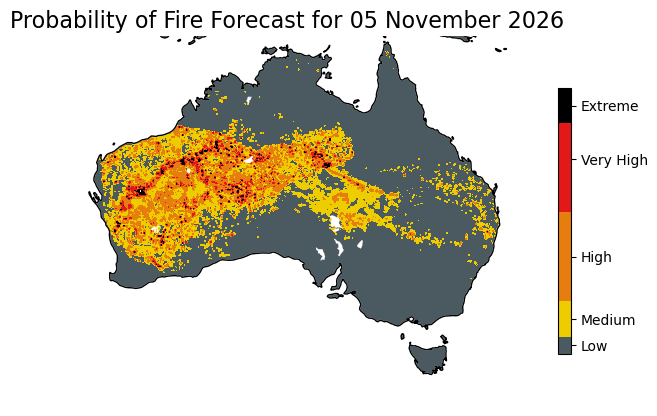

In [ ]:
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines(linewidth=1)

fig = ax.contourf(sub_ds.longitude, sub_ds.latitude, fires,levels=levels,vmin=0,vmax=0.006,transform=ccrs.PlateCarree(),cmap=test)

ax.add_feature(cart.feature.OCEAN,zorder=1,edgecolor='k',color='white')
ax.add_feature(cart.feature.BORDERS,linewidth=0.5,color='white')
ax.add_feature(cart.feature.LAKES,color='white', edgecolor='k', linewidth=0.2, zorder=2)

states_provinces = cart.feature.NaturalEarthFeature(
        category='cultural',
        name='admin_1_states_provinces_lines',
        scale='50m',
        edgecolor='black'
)

for spine in ax.spines.values():
   spine.set_visible(False)

cbar = plt.colorbar(fig,ticks=[0.0002,0.0008,0.0022,0.0044,0.0056],fraction=0.025, pad=0.04)
cbar.ax.set_yticklabels(['Low', 'Medium','High', 'Very High', 'Extreme'])

plt.title(plot_title, fontsize=16)

plt.tight_layout()

plt.savefig('./outputs/My_PoF_Plot.png', dpi=300)

